# DSCI 552 — Homework 4
**Seonmin Kim**

Time Series Classification Part 2: Binary and Multiclass Classification (AReM), plus ISLR 4.8.3 and 4.8.7.

## 0. Setup — data loading, train/test split, feature extraction (reused from Homework 3)
Per the assignment note, the Homework 3 feature creation code is included since it is needed here.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

DATA_DIR = Path("../data/AReM")

COLS = ["time", "avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

def load_instance(path):
    df = pd.read_csv(path, comment="#", header=None,
                     sep=r"[,\s]+", engine="python",
                     names=range(8))
    df = df.dropna(axis=1, how="all")
    df = df.iloc[:, 1:7]
    df.columns = COLS[1:]
    return df.astype(float)

ACTIVITIES = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]

instances = []
for act in ACTIVITIES:
    for f in sorted((DATA_DIR / act).glob("*.csv")):
        num = int(f.stem.replace("dataset", ""))
        instances.append({"activity": act, "num": num, "data": load_instance(f)})

print(len(instances))

88


In [2]:
def is_test(inst):
    if inst["activity"] in ("bending1", "bending2"):
        return inst["num"] in (1, 2)
    return inst["num"] in (1, 2, 3)

test = [i for i in instances if is_test(i)]
train = [i for i in instances if not is_test(i)]
print(len(train), len(test))

69 19


In [3]:
def extract_features(ts_df):
    out = {}
    for k, col in enumerate(ts_df.columns, start=1):
        s = ts_df[col]
        out[f"min{k}"]       = s.min()
        out[f"max{k}"]       = s.max()
        out[f"mean{k}"]      = s.mean()
        out[f"median{k}"]    = s.median()
        out[f"std{k}"]       = s.std()
        out[f"1st_quart{k}"] = s.quantile(0.25)
        out[f"3rd_quart{k}"] = s.quantile(0.75)
    return out

## 2(a)i Scatter plots of selected features (time series 1, 2, 6), bending vs. other activities

['min1', 'mean1', 'max1', 'min2', 'mean2', 'max2', 'min6', 'mean6', 'max6']


    min1      mean1   max1  min2     mean2  max2  min6     mean6  max6  \
0  35.00  43.954500  47.40   0.0  0.426250  1.70   0.0  0.493292  1.79   
1  33.00  42.179812  47.75   0.0  0.696042  3.00   0.0  0.613521  2.18   
2  33.00  41.678063  45.75   0.0  0.535979  2.83   0.0  0.383292  1.79   
3  37.00  43.454958  48.00   0.0  0.378083  1.58   0.0  0.679646  5.26   
4  36.25  43.969125  48.00   0.0  0.413125  1.50   0.0  0.555312  2.96   

   bending  
0  bending  
1  bending  
2  bending  
3  bending  
4  bending  


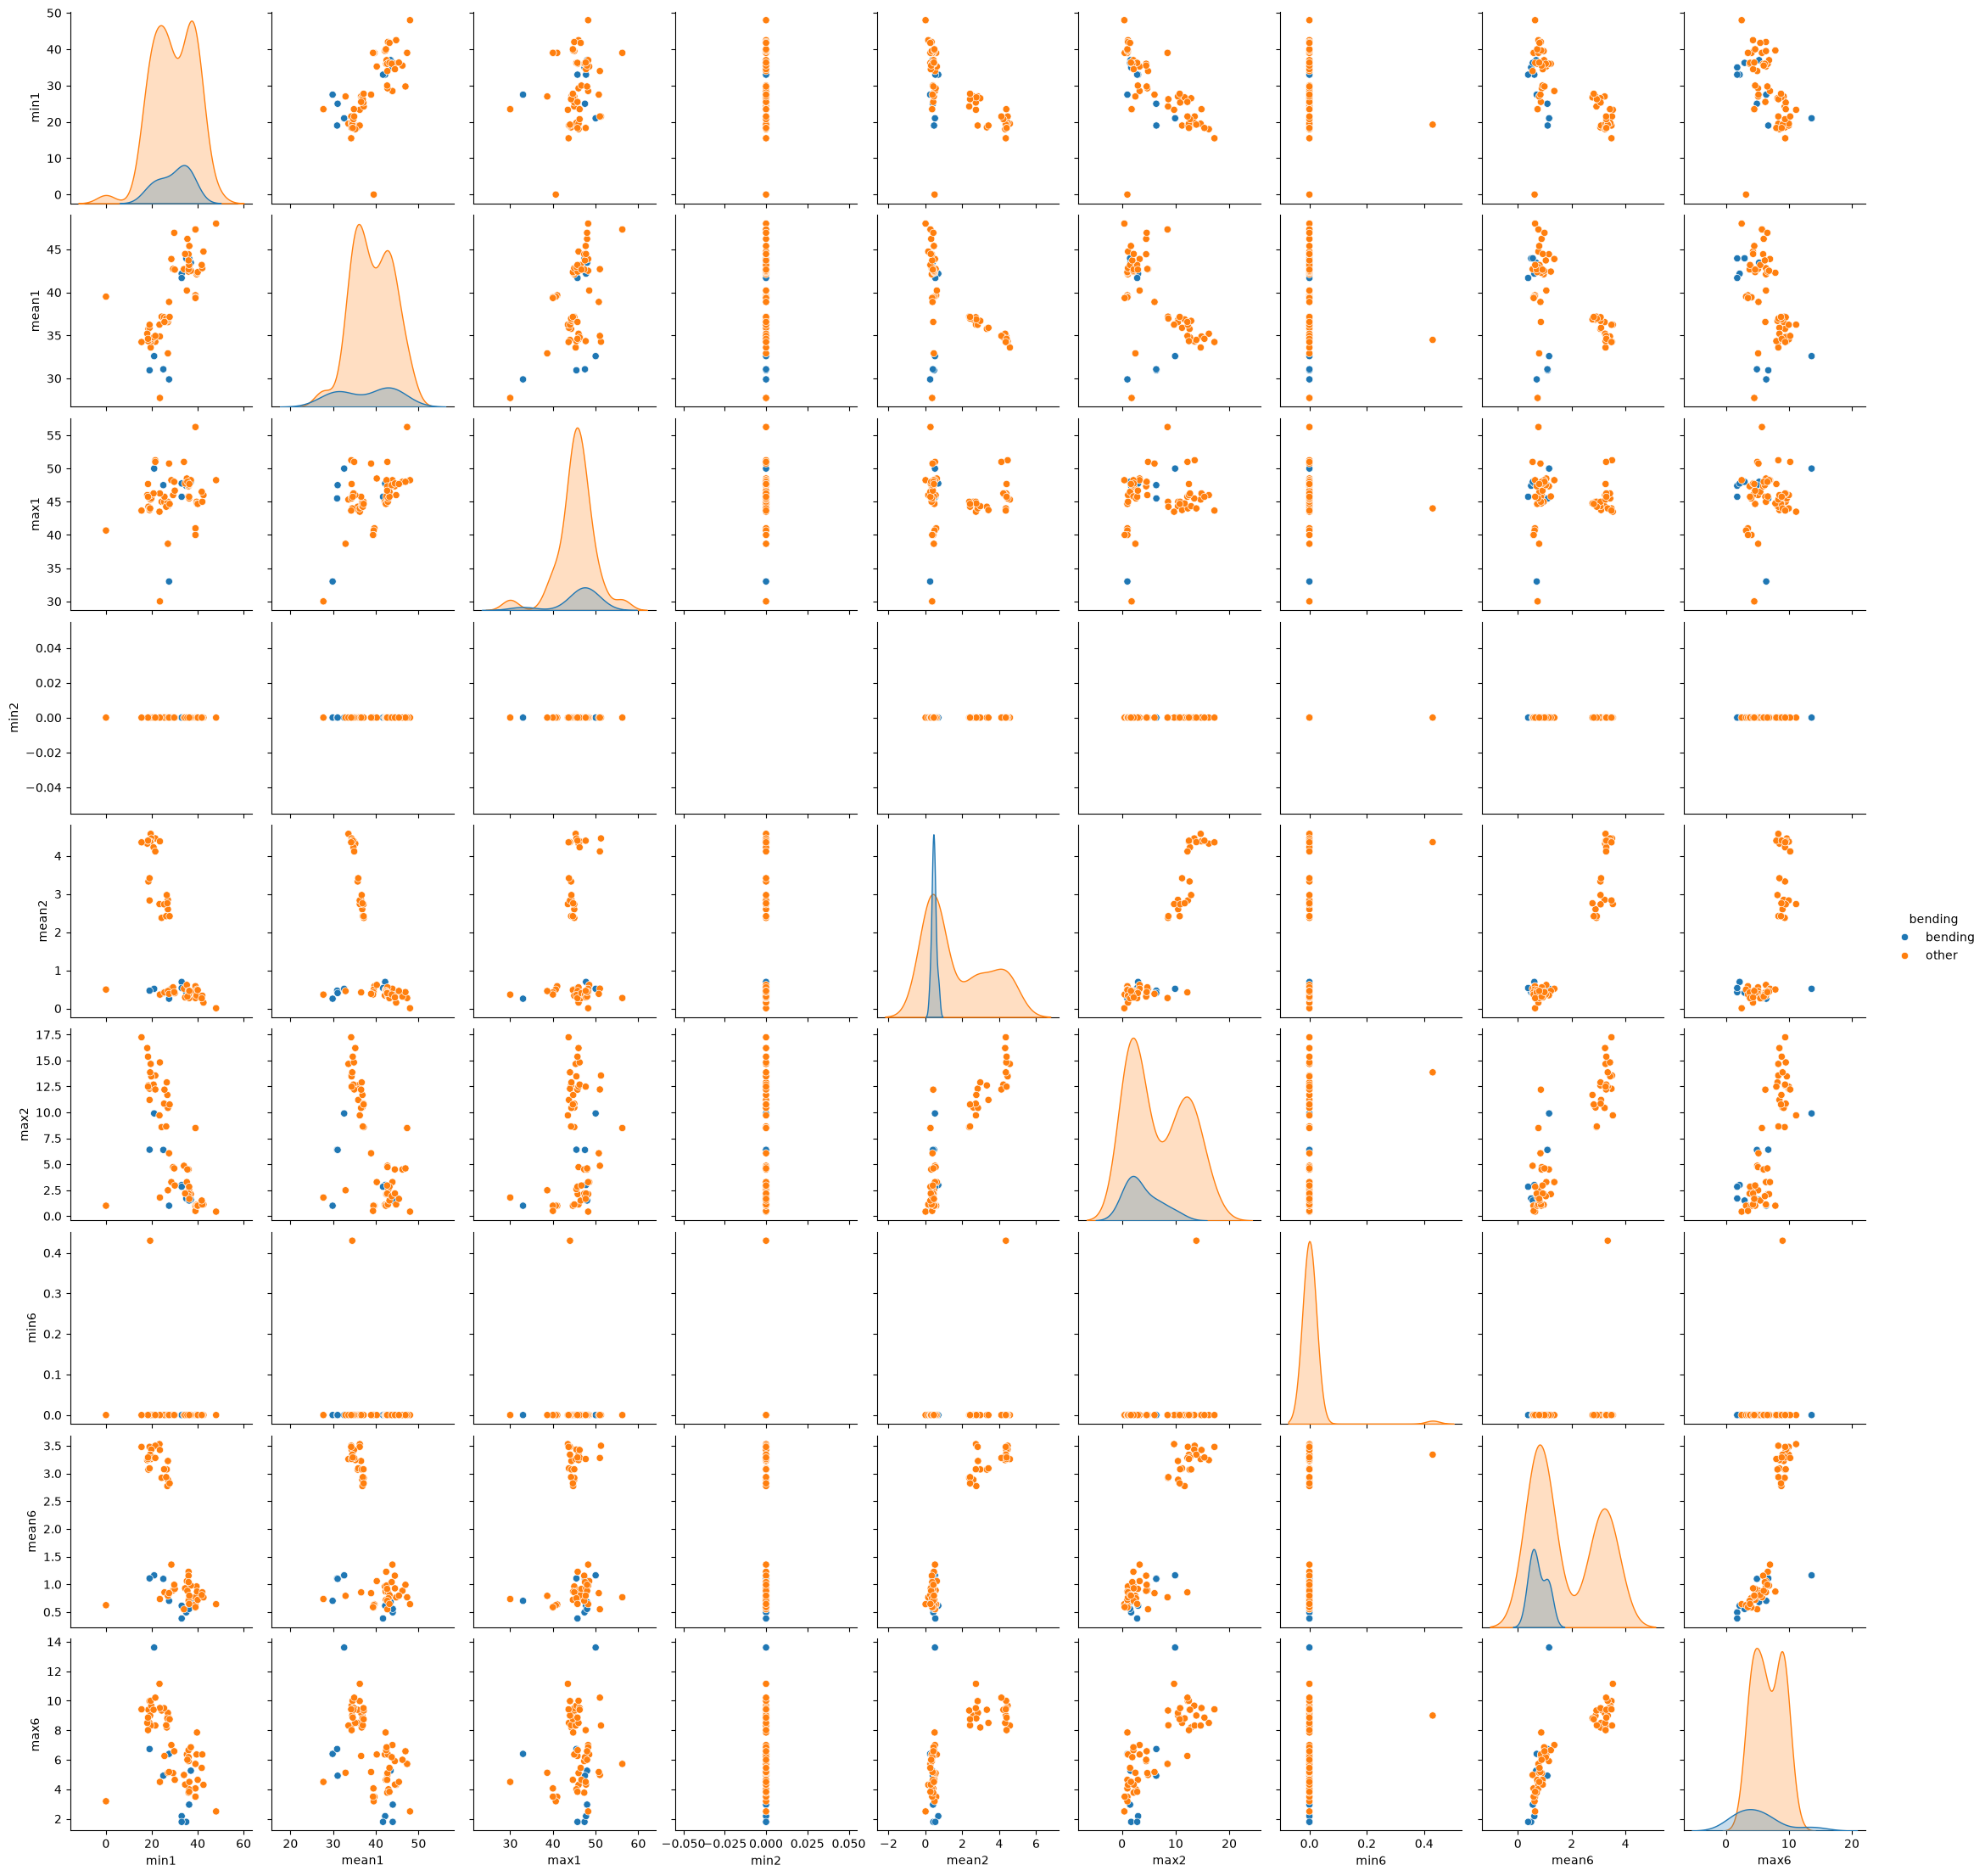

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

feats = ['min', 'mean', 'max']

cols = [f"{f}{k}" for k in (1, 2, 6) for f in feats]
print(cols)

df_i = pd.DataFrame([extract_features(i["data"]) for i in train])[cols]
df_i["bending"] = ["bending" if i["activity"].startswith("bending") else "other" for i in train]
print(df_i.head())

sns.pairplot(df_i, hue="bending")
plt.show()

Bending instances cluster in the low region of the mean/max of time series 2 and 6, while their mean of time series 1 is relatively high, so bending is fairly well separated from the other activities in several feature pairs. The separation is not perfect, however — bending partially overlaps with the static activities (sitting, lying), and min2/min6 are almost always 0, so they carry little discriminative power.

## 2(a)ii Break each time series into two halves and repeat the scatter plots

    min1      mean1   max1   min2      mean2   max2  min3     mean3  max3  \
0  36.50  44.057167  46.50  35.00  43.851833  47.40   0.0  0.381042  1.50   
1  33.75  43.278875  47.75  33.00  41.080750  46.00   0.0  0.673292  3.00   
2  33.00  41.621208  45.75  39.25  41.734917  43.67   0.0  0.623083  2.83   
3  39.00  44.117042  48.00  37.00  42.792875  46.50   0.0  0.250042  1.30   
4  36.67  43.486208  45.00  36.25  44.452042  48.00   0.0  0.378667  1.30   

   min4     mean4  max4  min11    mean11  max11  min12    mean12  max12  \
0   0.0  0.471458  1.70    0.0  0.598250   1.79    0.0  0.388333   1.50   
1   0.0  0.718792  2.86    0.0  0.640958   1.53    0.0  0.586083   2.18   
2   0.0  0.448875  1.12    0.0  0.419083   1.79    0.0  0.347500   1.50   
3   0.0  0.506125  1.58    0.0  0.815417   5.26    0.0  0.543875   4.06   
4   0.0  0.447583  1.50    0.0  0.524875   2.28    0.0  0.585750   2.96   

   bending  
0  bending  
1  bending  
2  bending  
3  bending  
4  bending  


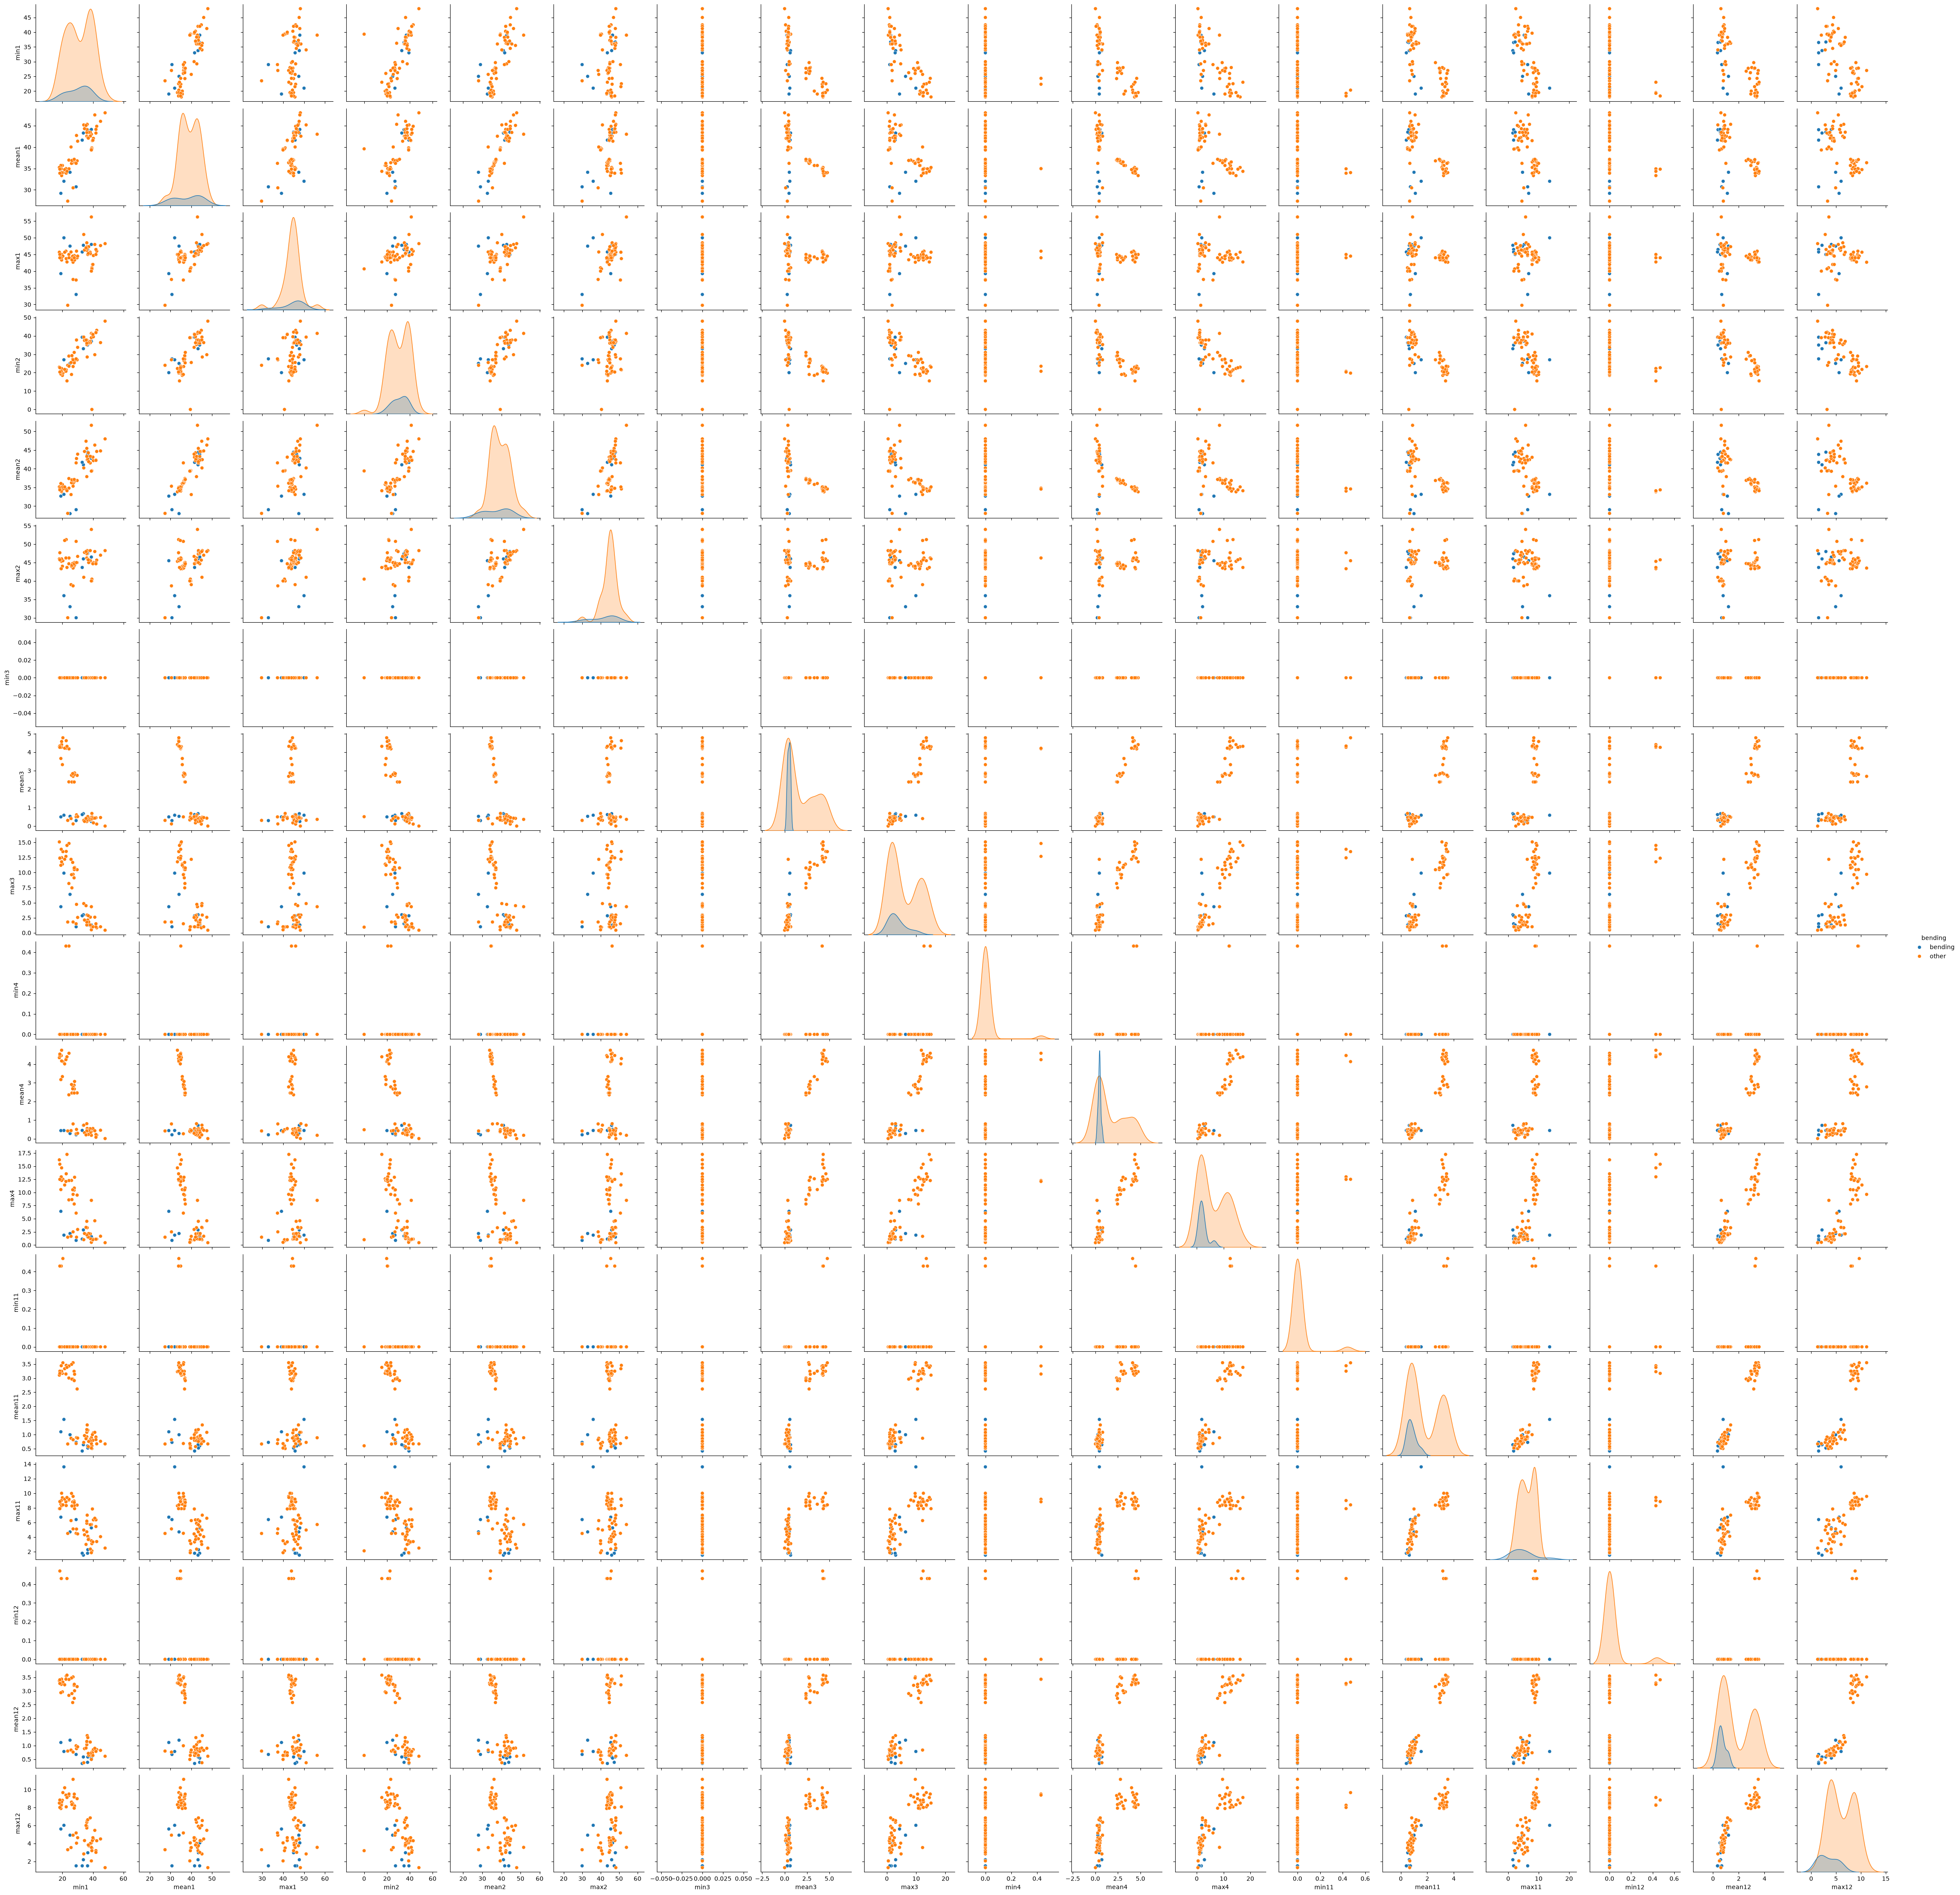

In [5]:
def extract_features_split(ts_df, l):
    out = {}
    k = 1
    for col in ts_df.columns:
        pieces = np.array_split(ts_df[col], l)
        for s in pieces:
            out[f"min{k}"]  = s.min()
            out[f"max{k}"]  = s.max()
            out[f"mean{k}"] = s.mean()
            k += 1
    return out

# with l=2, pieces 1-2 come from series 1, pieces 3-4 from series 2, pieces 11-12 from series 6
cols2 = [f"{f}{k}" for k in (1, 2, 3, 4, 11, 12) for f in feats]

df_i2 = pd.DataFrame([extract_features_split(i["data"], 2) for i in train])[cols2]
df_i2["bending"] = ["bending" if i["activity"].startswith("bending") else "other" for i in train]
print(df_i2.head())

sns.pairplot(df_i2, hue="bending")

Even after splitting, the distribution of each half and the bending-vs-other separation pattern are nearly identical to 2(a)i. The features from the first and second halves are strongly correlated with each other (the activities are roughly stationary over time), so splitting adds almost no new separating information. In short, there is no considerable difference.

## 2(a)iii Logistic regression with l ∈ {1,…,20}, feature selection, 5-fold stratified cross-validation for (l, p)

In [6]:
def extract_features_split(ts_df, l):
    out = {}
    k = 1
    for col in ts_df.columns:
        pieces = np.array_split(ts_df[col], l)
        for s in pieces:
            out[f"min{k}"]       = s.min()
            out[f"max{k}"]       = s.max()
            out[f"mean{k}"]      = s.mean()
            out[f"median{k}"]    = np.median(s)
            out[f"std{k}"]       = s.std(ddof=1)
            out[f"1st_quart{k}"] = np.quantile(s, 0.25)
            out[f"3rd_quart{k}"] = np.quantile(s, 0.75)
            k += 1
    return out


def build_features(inst_list, l):
    X = pd.DataFrame([extract_features_split(i["data"], l) for i in inst_list])
    y = np.array([1 if i["activity"].startswith("bending") else 0 for i in inst_list])
    return X, y

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
result = []

for l in range(1, 21):
    X, y = build_features(train, l)
    for p in [1, 2, 3, 4, 5, 7, 10, 15, 20]:
        if p > X.shape[1]:
            continue
        lr = LogisticRegression(C=1e6, max_iter=2000)
        pipe = Pipeline([
            ("rfe", RFE(lr, n_features_to_select=p, step=0.2)),
            ("lr", LogisticRegression(C=1e6, max_iter=2000)),
        ])
        acc = cross_val_score(pipe, X, y, cv=cv).mean()
        result.append({"l": l, "p": p, "cv_acc": acc})

res = pd.DataFrame(result).sort_values("cv_acc", ascending=False)
print(res.head(10))
best = res.iloc[0]

      l   p    cv_acc
4     1   5  1.000000
6     1  10  1.000000
20    3   3  0.985714
7     1  15  0.985714
8     1  20  0.985714
21    3   4  0.985714
5     1   7  0.984615
179  20  20  0.971429
35    4  20  0.971429
34    4  15  0.971429


In [8]:
print(best)

l         1.0
p         5.0
cv_acc    1.0
Name: 4, dtype: float64


**The wrong way to cross-validate here**

1. Run RFE on all 69 training instances to pick the "best" p features first.
2. Then run 5-fold CV using only those p features.

This looks natural but it is cheating. In each CV round, the held-out fold is supposed to play the role of unseen data. In step 1, however, RFE looked at that held-out fold too when deciding which features separate bending well — information from the "test" fold has already leaked into the feature selection. This is **data leakage**, and it inflates the CV score: the whole point of CV is to estimate performance on unseen data, and that estimate becomes optimistically biased. The bias is especially severe here because the number of features (up to 840) exceeds the number of instances (69) — among hundreds of features, some will fit the held-out data well purely by chance.

**The right way**

In every fold round:
1. Run RFE using only the 4 training folds to select p features.
2. Fit logistic regression on those same 4 folds.
3. Score on the remaining fold.

The average over the 5 rounds is the CV score for that (l, p). The key principle: feature selection is part of training, and every step that belongs to training must happen inside the training portion of each fold. It is fine that different features may be selected in different rounds — what we are measuring is the performance of the entire procedure. Putting RFE inside a `Pipeline` passed to `cross_val_score`, as above, implements this correctly and automatically.

## 2(a)iv Confusion matrix, ROC and AUC on training data; coefficients and p-values

selected features: ['3rd_quart1', 'min5', 'max5', '1st_quart5', 'max6']
[[60  0]
 [ 0  9]]
const         21.799678
3rd_quart1    -7.715604
min5           4.410464
max5           6.892916
1st_quart5     4.781862
max6          -3.687497
dtype: float64
const         0.999999
3rd_quart1    0.999986
min5          0.999989
max5          0.999991
1st_quart5    0.999994
max6          0.999989
dtype: float64


/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation 

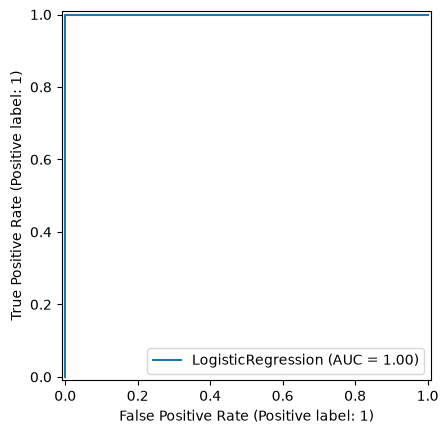

In [9]:
from sklearn.metrics import confusion_matrix, RocCurveDisplay
import statsmodels.api as sm

# 1. rebuild the data with the best (l, p)
best_l, best_p = int(best["l"]), int(best["p"])
X, y = build_features(train, best_l)

# 2. RFE on the full training set (OK here: this is the final model, not CV)
rfe = RFE(LogisticRegression(C=1e6, max_iter=2000),
          n_features_to_select=best_p, step=0.2).fit(X, y)
X_sel = X.loc[:, rfe.support_]
print("selected features:", list(X_sel.columns))

# 3. fit the final model and predict on train
clf = LogisticRegression(C=1e6, max_iter=2000).fit(X_sel, y)
y_pred = clf.predict(X_sel)

# 4. confusion matrix, ROC, AUC
print(confusion_matrix(y, y_pred))
RocCurveDisplay.from_estimator(clf, X_sel, y)

# 5. coefficients and p-values (statsmodels)
logit = sm.Logit(y, sm.add_constant(X_sel)).fit(disp=0)
print(logit.params)
print(logit.pvalues)

## 2(a)v Test set evaluation and comparison with cross-validation accuracy

In [10]:
# 1. split the test time series with the same l and extract the same features
X_test, y_test = build_features(test, best_l)

# 2. keep only the features selected on the training set (reuse the fitted RFE from 2(a)iv)
X_test_sel = X_test.loc[:, rfe.support_]

# 3. score
test_acc = clf.score(X_test_sel, y_test)
print("test accuracy:", round(test_acc, 3))
print("CV accuracy:  ", round(best["cv_acc"], 3))
print(confusion_matrix(y_test, clf.predict(X_test_sel)))

test accuracy: 1.0
CV accuracy:   1.0
[[15  0]
 [ 0  4]]


## 2(a)vi Are the classes well-separated enough to cause instability?

Yes. Three pieces of evidence: (1) the scatter plots in 2(a)i already show bending to be almost linearly separable; (2) the training AUC is 1.0 and the test set is classified perfectly; (3) statsmodels raised separation/convergence warnings, with huge coefficients and unreliable p-values, exactly as seen in 2(a)iv.

Why this causes instability, in one line: under perfect separation the likelihood keeps improving as the coefficients grow, so the MLE diverges (β → ∞), and the estimated coefficients and their p-values become numerically untrustworthy.

## 2(a)vii Class imbalance and case-control sampling

[[60  0]
 [ 0  9]]


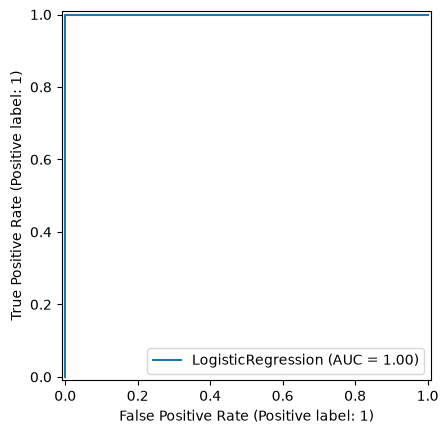

In [11]:
rng = np.random.default_rng(0)
other_idx = np.where(y == 0)[0]
keep = rng.choice(other_idx, size=9, replace=False)
idx = np.concatenate([np.where(y == 1)[0], keep])

X_cc, y_cc = X_sel.iloc[idx], y[idx]
clf_cc = LogisticRegression(C=1e6, max_iter=2000).fit(X_cc, y_cc)

# intercept correction: beta0 + log(pi/(1-pi)) - log(n1_sample/n0_sample)
pi = y.mean()                                # true bending proportion, 9/69
clf_cc.intercept_ += np.log(pi / (1 - pi))   # sample is 1:1, so the second term is log(1) = 0

# evaluate the corrected model on the training set
print(confusion_matrix(y, clf_cc.predict(X_sel)))
RocCurveDisplay.from_estimator(clf_cc, X_sel, y)

As the confusion matrices show (train: 60 vs. 9, test: 15 vs. 4), the classes are imbalanced. I therefore applied case-control sampling: 9 of the 60 "other" instances were drawn at random, the model was refit on the balanced data (9 bending + 9 other), and the prior distorted by the 1:1 sampling was restored through the intercept correction β₀ + log(π/(1−π)) (ISLR 4.6.3).

After the correction, the training confusion matrix is [[60, 0], [0, 9]] and the AUC is 1.0 — identical to the original model. Performance was preserved even though 85% of the data was discarded during fitting, which reflects how strong the bending-vs-other separation is; in this problem the imbalance has no practical adverse effect.

## 2(b)i L1-penalized logistic regression, cross-validating (l, λ)

In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegressionCV

results_l1 = []

for l in range(1, 21):
    X, y = build_features(train, l)
    pipe = Pipeline([
        ("sc", StandardScaler()),
        ("lr", LogisticRegressionCV(
            penalty='l1',
            solver="liblinear",
            Cs=10,
            cv=StratifiedKFold(5, shuffle=True, random_state=0),
            max_iter=5000,
        ))
    ])
    acc = cross_val_score(pipe, X, y,
        cv=StratifiedKFold(5, shuffle=True, random_state=1)).mean()
    results_l1.append({"l": l, "cv_acc": acc})

res_l1 = pd.DataFrame(results_l1).sort_values("cv_acc", ascending=False)
print(res_l1.head())
best_l1 = res_l1.iloc[0]

/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/

/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/

/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/

/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/

/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/

...

/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/

/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/

/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/

     l    cv_acc
0    1  0.970330
1    2  0.941758
2    3  0.941758
17  18  0.941758
19  20  0.928571


/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/

## 2(b)ii L1 penalization vs. p-value-based variable selection

- p-value/RFE approach (2(a)iii): l = 1, CV accuracy 1.0
- L1 approach: l = 1, CV accuracy 0.970

1. **Performance:** the p-value/RFE approach was marginally higher (1.0 vs. 0.97), but with 69 instances this difference amounts to about two instances, so it is not meaningful.
2. **Ease of implementation:** the RFE approach required several stages (a double loop, RFE, and a separate statsmodels fit for the p-values), whereas L1 handles feature selection and λ selection automatically inside a single `LogisticRegressionCV`. L1 is far easier to implement.

Both methods selected l = 1 and performed at essentially the same level. However, L1 builds variable selection into the fitting itself, making the implementation much simpler, and its regularization also naturally resolves the coefficient instability caused by perfect separation. Practically, the L1 approach is the better choice.

## 2(c)i L1-penalized multinomial regression for all seven activities

In [13]:
def build_features_multi(inst_list, l):
    X = pd.DataFrame([extract_features_split(i["data"], l) for i in inst_list])
    y = np.array([i["activity"] for i in inst_list])
    return X, y

results_mc = []
for l in range(1, 21):
    X, y = build_features_multi(train, l)
    pipe = Pipeline([
        ("sc", StandardScaler()),
        ("lr", LogisticRegressionCV(penalty='l1', solver="saga", Cs=5,
                                    cv=StratifiedKFold(5, shuffle=True,
                                    random_state=0),
                                    max_iter=5000)),
    ])
    acc = cross_val_score(pipe, X, y,
                cv=StratifiedKFold(5, shuffle=True, random_state=1)).mean()
    results_mc.append({"l": l, "cv_acc": acc})

res_mc = pd.DataFrame(results_mc).sort_values("cv_acc", ascending=False)
print(res_mc.head())

best_l_mc = int(res_mc.iloc[0]["l"])

/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instea

/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/

/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/

/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/

/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/

...

/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/

/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/

/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


   l    cv_acc
0  1  0.884615
2  3  0.856044
3  4  0.841758
4  5  0.841758
6  7  0.841758


/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
/Users/sunminkim/Projects/Kim_Seonmin_HW4/.venv/lib/python3.14/site-packages/

test error: 0.105


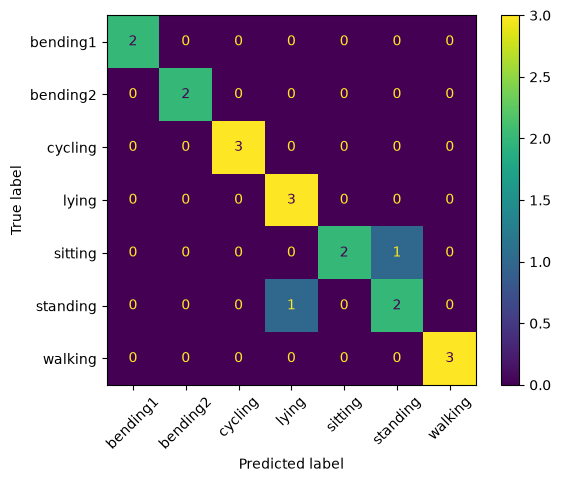

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay

X_tr, y_tr = build_features_multi(train, best_l_mc)
X_te, y_te = build_features_multi(test, best_l_mc)    # test must use the same l

final = Pipeline([("sc", StandardScaler()),
                  ("lr", LogisticRegressionCV(penalty="l1", solver="saga", Cs=5,
                                              cv=StratifiedKFold(5, shuffle=True, random_state=0),
                                              max_iter=5000))]).fit(X_tr, y_tr)

test_err = 1 - final.score(X_te, y_te)
print("test error:", round(test_err, 3))
ConfusionMatrixDisplay.from_estimator(final, X_te, y_te, xticks_rotation=45)

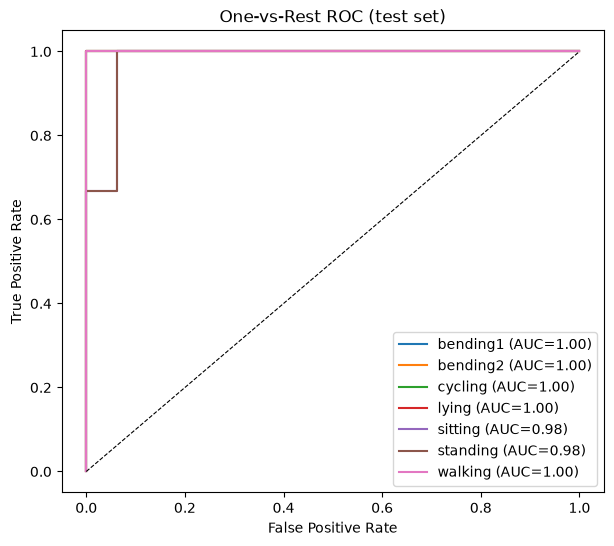

In [15]:
# multiclass ROC: one-vs-rest — one "this class vs. the rest" curve per class
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

classes = final.classes_
y_bin = label_binarize(y_te, classes=classes)   # 7-class labels -> seven 0/1 columns
proba = final.predict_proba(X_te)               # per-class probabilities

plt.figure(figsize=(7, 6))
for j, c in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_bin[:, j], proba[:, j])
    plt.plot(fpr, tpr, label=f"{c} (AUC={auc(fpr, tpr):.2f})")
plt.plot([0, 1], [0, 1], "k--", lw=0.8)          # chance line
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("One-vs-Rest ROC (test set)")
plt.legend()
plt.show()

## 2(c)ii Naïve Bayes with Gaussian and Multinomial priors

In [16]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import MinMaxScaler

gnb = GaussianNB().fit(X_tr, y_tr)
print("Gaussian NB test error:", round(1 - gnb.score(X_te, y_te), 3))

mm = MinMaxScaler().fit(X_tr)                        # fit on train only
mnb = MultinomialNB().fit(mm.transform(X_tr), y_tr)
print("Multinomial NB test error:", round(1 - mnb.score(mm.transform(X_te), y_te), 3))

Gaussian NB test error: 0.105
Multinomial NB test error: 0.211


## 2(c)iii Which method is better for multiclass classification here?

The L1-penalized multinomial logistic regression and Gaussian Naïve Bayes tied on test error at 0.105, while Multinomial Naïve Bayes was the worst at 0.211 — its count-data assumption is a poor fit for these continuous features. Logistic regression and Gaussian NB are tied on a test set of only 19 instances, but logistic regression requires no feature-independence assumption and performs variable selection through the L1 penalty, so I judge the L1-penalized multinomial logistic regression to be the better method for this problem. That said, Gaussian NB was a strong baseline — much faster and simpler.

## 3. ISLR 4.8.3

**Step 1 — the Bayes classifier's rule.** An observation x is assigned to the class k that maximizes πₖ·fₖ(x), where πₖ is the prior and fₖ is the class-k normal density. Taking logs preserves the ordering, so we maximize log(πₖ fₖ(x)).

**Step 2 — substitute the normal density, keeping the class subscript k on σ²:**

$$\delta_k(x) = \log \pi_k - \log(\sqrt{2\pi}\,\sigma_k) - \frac{(x-\mu_k)^2}{2\sigma_k^2}$$

Expanding the square:

$$\delta_k(x) = -\frac{1}{2\sigma_k^2}\,x^2 + \frac{\mu_k}{\sigma_k^2}\,x - \frac{\mu_k^2}{2\sigma_k^2} - \log\sigma_k + \log\pi_k$$

**Step 3 — the fate of the x² term decides the conclusion:**

- **LDA** (common σₖ = σ): the x² coefficient −1/(2σ²) is identical for every class, so it cancels when classes are compared, and the discriminant is linear in x (textbook Eq. 4.18) — the boundary is a line.
- **QDA** (class-specific σₖ): the x² coefficient −1/(2σₖ²) depends on k, so it does not cancel. The discriminant is **quadratic** in x, hence the Bayes classifier is quadratic, not linear. ∎

(Setting σₖ² = σ² makes the quadratic term vanish and recovers the linear LDA discriminant — LDA is the special case of QDA.)

## 4. ISLR 4.8.7

Given:

- X for dividend-paying companies: Normal(μ = 10, σ² = 36)
- X for non-paying companies: Normal(μ = 0, σ² = 36) (common variance)
- 80% of companies pay a dividend: π_yes = 0.8
- Question: P(Yes | X = 4)?

**Structure — Bayes' theorem:**

$$P(\text{Yes}\mid X=4) = \frac{\pi_{yes}\, f_{yes}(4)}{\pi_{yes}\, f_{yes}(4) + \pi_{no}\, f_{no}(4)}$$

**Computation.** In the normal density $f(x) = \frac{1}{\sqrt{2\pi}\sigma} e^{-(x-\mu)^2/2\sigma^2}$, the constant $\frac{1}{\sqrt{2\pi}\sigma}$ is common to numerator and denominator (possible because σ² is shared), so it cancels. Only the exponentials remain:

- Yes: $e^{-(4-10)^2/72} = e^{-36/72} = e^{-0.5} \approx 0.6065$
- No: $e^{-(4-0)^2/72} = e^{-16/72} = e^{-2/9} \approx 0.8007$

Substituting:

$$P(\text{Yes}\mid X=4) = \frac{0.8 \times 0.6065}{0.8 \times 0.6065 + 0.2 \times 0.8007} = \frac{0.4852}{0.4852 + 0.1601} \approx 0.752$$

**Answer: about 75.2%.**

In [17]:
num = 0.8 * np.exp(-0.5)
den = 0.8 * np.exp(-0.5) + 0.2 * np.exp(-16/72)
print(num / den)

0.7518524532975261


Note that X = 4 is actually closer to the "No" mean (0) than to the "Yes" mean (10), yet the Yes probability is still about 75%. This is the power of the prior: the evidence (x = 4) points slightly toward No, but dividend-paying companies are so much more common (8:2) that the evidence cannot overturn the prior.

---
## AI Disclosure
Claude was used for repository scaffolding, reusing the Homework 3 loading/feature-extraction code, hints on how to approach each part, and translating my Korean write-ups into English. All modeling code and answers are my own.